# Model 1: Logistic Regression

**PathSnap map matching.** Owner: Krishna Jha.

**What it is.** A linear, probabilistic classifier. It computes a weighted sum of the 19 features and turns it into a probability with the sigmoid function:

$$P(\text{true arc}) = \sigma(w_0 + w_1 x_1 + \dots + w_{19} x_{19})$$

**Why we chose it for this problem**
- **Calibrated probabilities:** it is trained by minimising log loss, so its outputs behave like real probabilities. The HMM uses them directly as emission scores.
- **Interpretable:** each feature gets one weight, so we can see what the model relies on (for example, distance and direction).
- **Fast and tiny:** about 60 numbers in total, so it trains in about a second and predicts in under a millisecond per 1,000 fixes.
- **The reference:** the strong, simple model that the more complex models must beat.

**Limits**
- The decision boundary is linear, so interactions must be built into the features. That is why `cos_heading_weighted` (direction × speed confidence) exists.

**Two configurations compared**
- `logreg`: unweighted.
- `logreg_balanced`: `class_weight="balanced"`, which up-weights the rare correct rows (~1 in 9).

**Configuration:** `StandardScaler` → `LogisticRegression(C=1.0, max_iter=2000)` (L2 regularisation, lbfgs solver).
**Loss:** binary cross-entropy with L2 penalty. It is solved directly, not in epochs, so there is no loss curve.

In [1]:
import sys, os, json, time, tempfile, warnings, logging
from pathlib import Path
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn
from IPython.display import Markdown, display
from sklearn.calibration import calibration_curve
from sklearn.metrics import ConfusionMatrixDisplay

from src import evaluate as ev, plot_style as ps
from src.config import SEED, N_FOLDS
from src.features import FEATURE_COLUMNS, load_or_build
from src.model_zoo import REGISTRY

warnings.filterwarnings("ignore", message=".*encountered in matmul")   # spurious numpy/Accelerate warning on macOS
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
ps.apply_style()
%matplotlib inline
pd.set_option("display.float_format", "{:,.4f}".format)
print(f"sklearn {sklearn.__version__} | numpy {np.__version__} | pandas {pd.__version__} | seed {SEED} | folds {N_FOLDS}")

sklearn 1.7.2 | numpy 2.2.6 | pandas 2.3.3 | seed 42 | folds 5


## 1. Data

The candidate table (KKR's `python -m src.build_dataset`) has one row per (GPS fix, candidate arc within 50 m), labelled 1 if it is the correct arc. The 19 features come from `src/features.py` and use only the GPS track and the road network.

In [2]:
PROC = PROJECT_ROOT / "data" / "processed"
if not (PROC / "fixes_train.parquet").exists():
    raise FileNotFoundError("Run `python -m src.build_dataset` first.")
cand_tr, cand_te = load_or_build("train"), load_or_build("student_test")
fix_tr = pd.read_parquet(PROC / "fixes_train.parquet")
fix_te = pd.read_parquet(PROC / "fixes_student_test.parquet")

pd.DataFrame({
    "trips": [cand_tr.trip_id.nunique(), cand_te.trip_id.nunique()],
    "GPS fixes": [len(fix_tr), len(fix_te)],
    "labelled fixes": [int(fix_tr.fix_valid.sum()), int(fix_te.fix_valid.sum())],
    "candidate rows": [len(cand_tr), len(cand_te)],
    "labelled rows used for training": [int(cand_tr.fix_valid.sum()), "—"],
    "share of correct rows": [cand_tr[cand_tr.fix_valid].label.mean(), cand_te[cand_te.fix_valid].label.mean()],
}, index=["train (80 trips)", "student_test (10 trips)"])

,trips,GPS fixes,labelled fixes,candidate rows,labelled rows used for training,share of correct rows
train (80 trips),80,208417,187867,1869589,1848746,0.1002
student_test (10 trips),10,19160,19143,209579,—,0.0913


## Evaluation protocol

- **5-fold GroupKFold by trip** on the 80 train trips. A whole trip stays in one fold, because consecutive fixes are nearly identical and a row-level split would leak.
- **Preprocessing inside each fold:** the `StandardScaler` is part of the sklearn `Pipeline`, so it is fitted on the training fold only.
- **Final test:** refit on all 80 train trips, then evaluate **once** on the 10 student-test trips. Evaluator trips are never used.

| Metric | Meaning |
|---|---|
| Top-1 accuracy | Per labelled GPS fix: is the highest-scored candidate the correct arc? Fixes with no correct candidate count as wrong. |
| Macro F1, precision, recall, accuracy | On candidate rows at threshold 0.5. Macro F1 is used because only ~1 row in 9 is correct. |
| Log loss | Quality of the probabilities (lower is better). The HMM uses them as emission scores. |
| Route continuity | Share of consecutive predictions that are the same arc or directly connected. |
| Train F1 − CV F1 | A large positive gap means overfitting. |

### Reference: nearest-arc baseline
Always pick the closest candidate. No training. This is the score to beat.

In [3]:
base_cv = ev.group_cv(None, {}, cand_tr, fix_tr, FEATURE_COLUMNS, n_folds=N_FOLDS, verbose=False)
base_st = ev.baseline_metrics(cand_te, fix_te)
print(f"Nearest-arc baseline: CV Top-1 {base_cv.top1.mean():.4f} | student-test Top-1 {base_st['top1']:.4f}")

Nearest-arc baseline: CV Top-1 0.5585 | student-test Top-1 0.5381


In [4]:
def fold_plot(folds_by_name):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
    for ax, metric, title in [(axes[0], "macro_f1", "Macro F1 per fold"), (axes[1], "top1", "Top-1 accuracy per fold")]:
        for i, (name, f) in enumerate(folds_by_name.items()):
            ax.plot(f.fold, f[metric], marker="o", ms=6, label=f"{name} (mean {f[metric].mean():.3f})",
                    color=[ps.BLUE, ps.ORANGE, ps.AQUA][i % 3])
        if metric == "top1":
            ax.plot(base_cv.fold, base_cv.top1, marker="s", ls="--", color=ps.MUTED, label=f"baseline (mean {base_cv.top1.mean():.3f})")
        ax.set(title=title, xlabel="validation fold (GroupKFold by trip)", ylim=(0.4, 1.0)); ax.set_xticks(range(N_FOLDS))
        ax.legend(loc="lower right")
    plt.show()

def st_table(rows):
    cols = ["top1", "macro_f1", "precision", "recall", "accuracy", "log_loss", "route_continuity", "candidate_miss_rate"]
    return pd.DataFrame({k: {c: v.get(c) for c in cols} for k, v in rows.items()}).T

def confusion(results):
    fig, axes = plt.subplots(1, len(results), figsize=(4.6 * len(results), 3.8))
    for ax, (name, m) in zip(np.atleast_1d(axes), results.items()):
        ConfusionMatrixDisplay(np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]]),
                               display_labels=["wrong arc", "true arc"]).plot(ax=ax, colorbar=False, cmap="Blues", values_format=",")
        ax.set_title(f"{name}: student test"); ax.grid(False)
    plt.tight_layout(); plt.show()

def calibration(probs):
    valid = cand_te.fix_valid.to_numpy()
    y = cand_te.label.to_numpy()[valid]
    fig, ax = plt.subplots(figsize=(5.2, 4.4))
    ax.plot([0, 1], [0, 1], ls="--", color=ps.MUTED, lw=1, label="perfectly calibrated")
    for i, (name, p) in enumerate(probs.items()):
        frac, mean_p = calibration_curve(y, p[valid], n_bins=10, strategy="quantile")
        ax.plot(mean_p, frac, marker="o", color=[ps.BLUE, ps.ORANGE, ps.AQUA][i % 3], label=name)
    ax.set(title="Probability calibration (student test)", xlabel="predicted probability", ylabel="observed share of true arcs")
    ax.legend(loc="upper left"); plt.show()

def per_trip(prob):
    top = ev.top_candidates(cand_te, prob)
    rows = []
    for tid, f in fix_te[fix_te.fix_valid].groupby("trip_id"):
        hit = f.merge(top[top.trip_id == tid][["fix_idx", "label"]], on="fix_idx", how="left")["label"].fillna(0)
        base_top = ev.top_candidates(cand_te[cand_te.trip_id == tid], ev.baseline_scores(cand_te[cand_te.trip_id == tid]))
        base_hit = f.merge(base_top[["fix_idx", "label"]], on="fix_idx", how="left")["label"].fillna(0)
        rows.append({"trip": tid, "labelled fixes": len(f), "baseline Top-1": base_hit.mean(), "model Top-1": hit.mean()})
    d = pd.DataFrame(rows).set_index("trip")
    d["gain (points)"] = (d["model Top-1"] - d["baseline Top-1"]) * 100
    return d

def size_and_speed(model, name):
    with tempfile.TemporaryDirectory() as tmp:
        p = Path(tmp) / f"{name}.joblib"
        joblib.dump(model, p)
        mb = p.stat().st_size / 1e6
    X = cand_te[FEATURE_COLUMNS].to_numpy(float)
    t0 = time.perf_counter(); model.predict_proba(X); dt = time.perf_counter() - t0
    n_fix = cand_te[["trip_id", "fix_idx"]].drop_duplicates().shape[0]
    return {"saved size (MB)": mb, "predict time, all student-test rows (s)": dt, "ms per 1,000 fixes": dt / n_fix * 1e6}

## 2. Training: 5-fold cross-validation

In [5]:
specs = {n: REGISTRY[n] for n in ["logreg", "logreg_balanced"]}
for n, s in specs.items():
    print(n, "->", s.description)
cv = {n: ev.group_cv(s.factory, s.params, cand_tr, fix_tr, FEATURE_COLUMNS, n_folds=N_FOLDS, verbose=False) for n, s in specs.items()}
cv["logreg"][["fold", "n_val_trips", "macro_f1", "top1", "log_loss", "precision", "recall", "route_continuity",
              "train_macro_f1", "train_time_s", "infer_ms_per_1k_fixes"]]

logreg -> StandardScaler + LogisticRegression, C=1, unweighted
logreg_balanced -> StandardScaler + LogisticRegression, C=1, class_weight=balanced


,fold,n_val_trips,macro_f1,top1,log_loss,precision,recall,route_continuity,train_macro_f1,train_time_s,infer_ms_per_1k_fixes
0,0,16,0.9001,0.8592,0.0924,0.8176,0.8174,0.9418,0.8810,0.7726,0.8983
1,1,16,0.8907,0.8620,0.1065,0.8279,0.7816,0.9359,0.8820,0.8085,0.5167
2,2,16,0.8989,0.8430,0.1015,0.8290,0.8024,0.9468,0.8844,0.7941,0.4682
3,3,16,0.8530,0.7672,0.1538,0.7534,0.7339,0.9673,0.8936,0.6869,0.3395
4,4,16,0.8871,0.8495,0.0938,0.8063,0.7808,0.9234,0.8816,0.6762,0.4340


In [6]:
cv["logreg_balanced"][["fold", "n_val_trips", "macro_f1", "top1", "log_loss", "precision", "recall", "route_continuity",
                       "train_macro_f1", "train_time_s", "infer_ms_per_1k_fixes"]]

,fold,n_val_trips,macro_f1,top1,log_loss,precision,recall,route_continuity,train_macro_f1,train_time_s,infer_ms_per_1k_fixes
0,0,16,0.8212,0.8345,0.1813,0.5340,0.9579,0.9457,0.8127,1.1011,0.4752
1,1,16,0.8362,0.8385,0.1856,0.5800,0.9426,0.9395,0.8095,1.2031,0.3458
2,2,16,0.8284,0.8323,0.1777,0.5550,0.9398,0.9537,0.8163,1.1535,0.4312
3,3,16,0.7800,0.7411,0.2998,0.4870,0.9504,0.9609,0.8165,0.9262,0.3097
4,4,16,0.8097,0.8066,0.1872,0.5138,0.9462,0.9216,0.8150,1.1941,0.4084


In [7]:
summary = pd.DataFrame({n: {"CV macro F1": f"{f.macro_f1.mean():.4f} ± {f.macro_f1.std(ddof=1):.4f}",
                            "CV Top-1": f"{f.top1.mean():.4f} ± {f.top1.std(ddof=1):.4f}",
                            "CV log loss": f"{f.log_loss.mean():.4f}",
                            "train macro F1": f"{f.train_macro_f1.mean():.4f}",
                            "train − CV macro F1": f"{f.train_macro_f1.mean() - f.macro_f1.mean():+.4f}"} for n, f in cv.items()}).T
summary

,CV macro F1,CV Top-1,CV log loss,train macro F1,train − CV macro F1
logreg,0.8860 ± 0.0192,0.8362 ± 0.0393,0.1096,0.8845,-0.0015
logreg_balanced,0.8151 ± 0.0219,0.8106 ± 0.0408,0.2063,0.8140,-0.0011


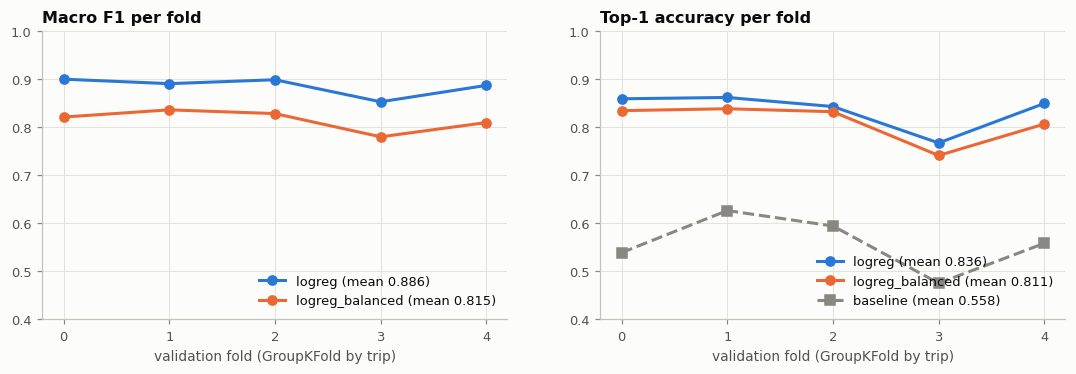

In [8]:
fold_plot(cv)

## 3. Testing on the 10 student-test trips
Refit on all 80 train trips, then evaluate once.

In [9]:
fitted, probs, st = {}, {}, {}
for n, s in specs.items():
    fitted[n], probs[n], fit_s, pred_s = ev.fit_predict(s.factory, s.params, cand_tr, cand_te, FEATURE_COLUMNS)
    st[n] = ev.evaluate_predictions(cand_te, probs[n], fix_te)
    print(f"{n}: fit on {int(cand_tr.fix_valid.sum()):,} rows in {fit_s:.1f}s, predicted {len(cand_te):,} rows in {pred_s:.2f}s")
st_table({"nearest-arc baseline": base_st, **st})

logreg: fit on 1,848,746 rows in 0.9s, predicted 209,579 rows in 0.01s


logreg_balanced: fit on 1,848,746 rows in 1.5s, predicted 209,579 rows in 0.01s


,top1,macro_f1,precision,recall,accuracy,log_loss,route_continuity,candidate_miss_rate
nearest-arc baseline,0.5381,0.7459,0.5381,0.5383,0.9156,NaN,0.8210,0.0005
logreg,0.8440,0.8911,0.8035,0.8006,0.9639,0.0906,0.9445,0.0005
logreg_balanced,0.8134,0.8159,0.5266,0.9565,0.9175,0.1924,0.9466,0.0005


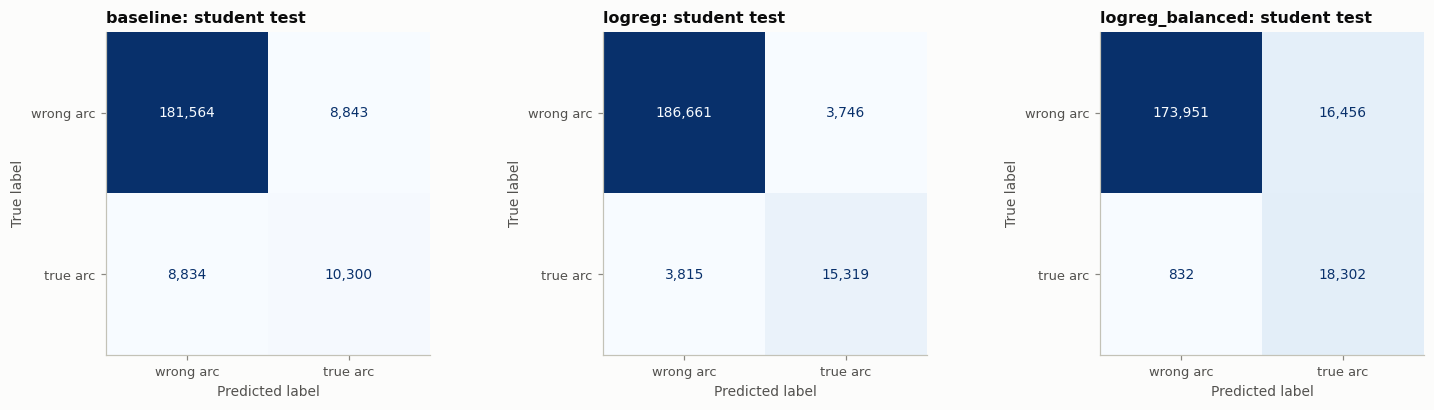

In [10]:
confusion({"baseline": base_st, "logreg": st["logreg"], "logreg_balanced": st["logreg_balanced"]})

## 4. What did the model learn?
Standardised coefficients: a positive weight means a larger value makes the candidate more likely to be the true arc. Features are standardised, so the sizes are comparable.

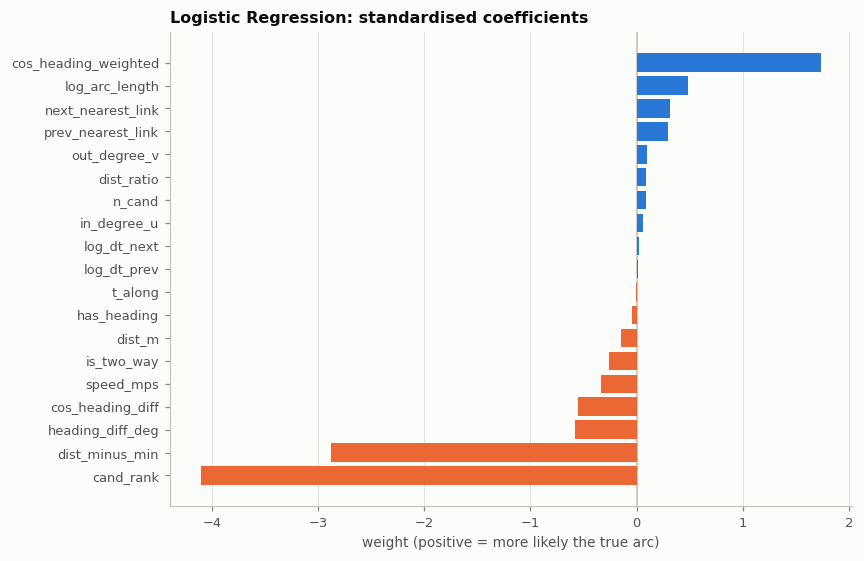

intercept: -8.950


,coefficient
cand_rank,-4.1014
dist_minus_min,-2.8728
cos_heading_weighted,1.7364
heading_diff_deg,-0.5835
cos_heading_diff,-0.5496
log_arc_length,0.4849


In [11]:
coef = pd.Series(fitted["logreg"].named_steps["clf"].coef_[0], index=FEATURE_COLUMNS).sort_values()
fig, ax = plt.subplots(figsize=(8, 5.6))
ax.barh(coef.index, coef.values, color=[ps.BLUE if v > 0 else ps.ORANGE for v in coef.values], zorder=3)
ax.axvline(0, color=ps.BASELINE, lw=1); ax.grid(axis="y", visible=False)
ax.set(title="Logistic Regression: standardised coefficients", xlabel="weight (positive = more likely the true arc)")
plt.show()
print(f"intercept: {fitted['logreg'].named_steps['clf'].intercept_[0]:.3f}")
coef.sort_values(key=abs, ascending=False).head(6).to_frame("coefficient")

## 5. Probability quality
If the model says 0.8, about 80% of such candidates should really be correct. Points on the dashed line mean well-calibrated probabilities, which is what the HMM needs.

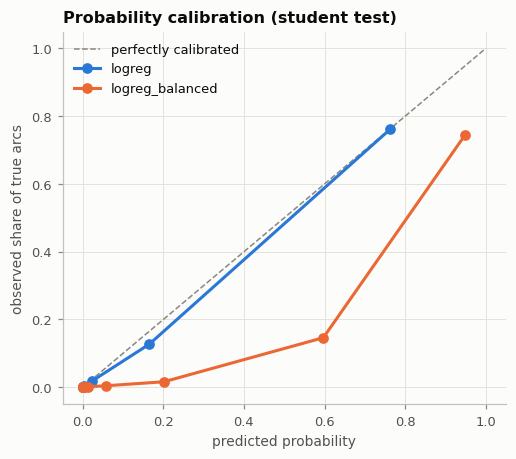

In [12]:
calibration(probs)

## 6. Accuracy per student-test trip

In [13]:
trips = per_trip(probs['logreg']); trips

,labelled fixes,baseline Top-1,model Top-1,gain (points)
trip,,,,
00000000,2503,0.5374,0.9377,40.0320
00000007,1354,0.4749,0.9018,42.6883
00000009,1049,0.5310,0.8427,31.1725
00000040,2995,0.5396,0.9058,36.6277
00000052,262,0.7710,0.9237,15.2672
00000056,3941,0.6907,0.8820,19.1322
00000065,768,0.6927,0.8203,12.7604
00000076,1486,0.4112,0.8466,43.5397
00000077,3911,0.4050,0.6786,27.3587


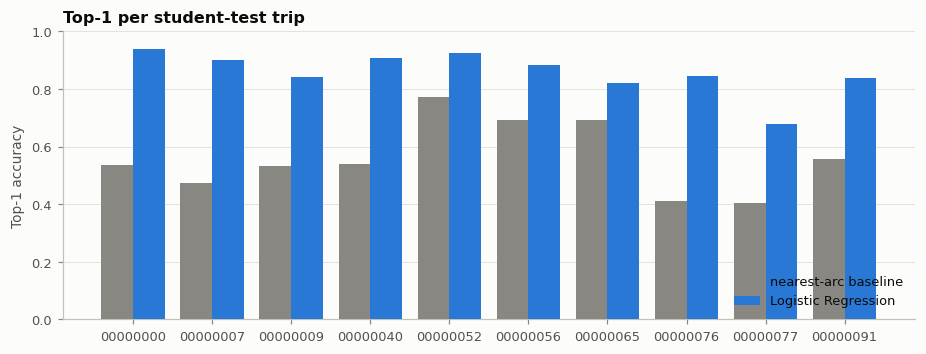

In [14]:
fig, ax = plt.subplots(figsize=(10, 3.4))
x = np.arange(len(trips))
ax.bar(x - 0.2, trips["baseline Top-1"], 0.4, color=ps.MUTED, label="nearest-arc baseline", zorder=3)
ax.bar(x + 0.2, trips["model Top-1"], 0.4, color=ps.BLUE, label="Logistic Regression", zorder=3)
ax.set_xticks(x, trips.index, rotation=0); ax.set(ylim=(0, 1), ylabel="Top-1 accuracy", title="Top-1 per student-test trip")
ax.legend(loc="lower right"); ax.grid(axis="x", visible=False); plt.show()

## 7. Model size and speed

In [15]:
pd.DataFrame({n: size_and_speed(m, n) for n, m in fitted.items()}).T

,saved size (MB),"predict time, all student-test rows (s)","ms per 1,000 fixes"
logreg,0.0019,0.0038,0.1996
logreg_balanced,0.0020,0.0041,0.2126


## 8. Summary (generated from the numbers above)

In [16]:
b = base_st["top1"]
lines = [f"- **Baseline** (nearest arc): {b:.1%} Top-1 on student test."]
for n in specs:
    r, f = st[n], cv[n]
    lines.append(f"- **{n}**: student-test Top-1 **{r['top1']:.1%}** ({(r['top1'] - b) * 100:+.1f} points vs baseline), "
                 f"macro F1 {r['macro_f1']:.3f}, log loss {r['log_loss']:.3f}; CV Top-1 {f.top1.mean():.1%} ± {f.top1.std(ddof=1):.1%}; "
                 f"train − CV F1 gap {f.train_macro_f1.mean() - f.macro_f1.mean():+.3f}.")
better = "logreg" if st["logreg"]["log_loss"] < st["logreg_balanced"]["log_loss"] and st["logreg"]["top1"] >= st["logreg_balanced"]["top1"] else None
if better:
    lines.append("- **Class weighting hurts here:** the unweighted model has both higher Top-1 and lower log loss. "
                 "Up-weighting the rare correct rows pushes probabilities upwards, so the unweighted configuration is kept.")
top3 = coef.abs().sort_values(ascending=False).index[:3].tolist()
lines.append(f"- **Most influential features:** {', '.join(top3)}.")
lines.append(f"- **Upper bound** from candidate misses: {1 - base_st['candidate_miss_rate']:.2%} Top-1.")
display(Markdown("\n".join(lines)))

- **Baseline** (nearest arc): 53.8% Top-1 on student test.
- **logreg**: student-test Top-1 **84.4%** (+30.6 points vs baseline), macro F1 0.891, log loss 0.091; CV Top-1 83.6% ± 3.9%; train − CV F1 gap -0.001.
- **logreg_balanced**: student-test Top-1 **81.3%** (+27.5 points vs baseline), macro F1 0.816, log loss 0.192; CV Top-1 81.1% ± 4.1%; train − CV F1 gap -0.001.
- **Class weighting hurts here:** the unweighted model has both higher Top-1 and lower log loss. Up-weighting the rare correct rows pushes probabilities upwards, so the unweighted configuration is kept.
- **Most influential features:** cand_rank, dist_minus_min, cos_heading_weighted.
- **Upper bound** from candidate misses: 99.95% Top-1.